# How Much of a Paycheque Does a Canadian Home Take? 45 Years of the Bank of Canada Affordability Index

**Author:** John Khan

**Question.** Is owning a home in Canada less affordable now than it has ever been, or does it only feel that way? And how much of the swing comes from mortgage rates rather than prices?

**Data (live from the Bank of Canada Valet API, https://www.bankofcanada.ca/valet/docs):**

| Series ID | What it is | Frequency | Starts |
|---|---|---|---|
| `INDINF_AFFORD_Q` | Housing affordability index: share of average household disposable income needed for mortgage payments and utilities on an average priced home | Quarterly | 1980 |
| `INDINF_NHPI_Q` | New Housing Price Index, year over year % change (Statistics Canada NHPI, table 18-10-0205-01, as republished by the Bank of Canada) | Quarterly | 1993 |
| `V80691335` | Posted 5 year conventional mortgage rate, chartered banks | Weekly | 1975 |

**How the Bank builds the index** (from https://www.bankofcanada.ca/rates/indicators/capacity-and-inflation-pressures/real-estate-market-definitions/): monthly payment on a mortgage equal to 95% of the six month average MLS resale price, 25 year amortization, at an effective rate that blends discounted 1, 3 and 5 year fixed and variable rates, plus utilities, divided by average household disposable income. Higher means less affordable. It reflects resale homes, not new builds, and it excludes property tax and mortgage insurance.

If the API is down, the notebook reads the snapshot it saved in `data/`.

In [1]:
import io, os, json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BLUE = "#011F5B"
RED = "#990000"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})
TITLE_FONT = {"family": "serif", "weight": "bold", "size": 15}

VALET = "https://www.bankofcanada.ca/valet/observations/{ids}/json"
SNAPSHOT_DIR = "data"

def valet(series, start=None, snapshot=None):
    """Pull one or more Bank of Canada Valet series into a DataFrame.
    If the live pull fails, fall back to a CSV snapshot saved next to the notebook
    (on Kaggle, upload the snapshot CSV as a dataset and point SNAPSHOT_DIR at it)."""
    ids = ",".join(series)
    params = {"start_date": start} if start else {}
    try:
        r = requests.get(VALET.format(ids=ids), params=params, timeout=60)
        r.raise_for_status()
        obs = r.json()["observations"]
        rows = []
        for o in obs:
            row = {"date": o["d"]}
            for s in series:
                v = o.get(s, {}).get("v")
                row[s] = float(v) if v not in (None, "") else np.nan
            rows.append(row)
        df = pd.DataFrame(rows)
        df["date"] = pd.to_datetime(df["date"])
        df = df.set_index("date").sort_index()
        if snapshot:
            os.makedirs(SNAPSHOT_DIR, exist_ok=True)
            df.to_csv(os.path.join(SNAPSHOT_DIR, snapshot))
        print(f"Live pull OK: {ids} ({len(df)} rows, {df.index.min().date()} to {df.index.max().date()})")
        return df
    except Exception as e:
        path = os.path.join(SNAPSHOT_DIR, snapshot or "missing.csv")
        print(f"Live pull failed ({e}). Reading snapshot {path}")
        return pd.read_csv(path, index_col="date", parse_dates=True)

def style(ax, title, ylabel=None):
    ax.set_title(title, fontdict=TITLE_FONT, loc="left", color=BLUE)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax

def save(fig, name):
    os.makedirs("charts", exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join("charts", name), dpi=150, bbox_inches="tight")
    plt.show()


## 1. Pull the data

In [2]:
q = valet(["INDINF_AFFORD_Q", "INDINF_NHPI_Q"], snapshot="quarterly_afford_nhpi.csv")
q = q.rename(columns={"INDINF_AFFORD_Q": "afford", "INDINF_NHPI_Q": "nhpi_yoy"})
q["afford_pct"] = q["afford"] * 100     # share of disposable income, in percent
posted = valet(["V80691335"], start="1980-01-01", snapshot="weekly_posted_5yr.csv").rename(columns={"V80691335": "posted5"})
q["posted5"] = posted["posted5"].resample("QS").mean().reindex(q.index)
q = q.dropna(subset=["afford"])
q.tail(8).round(2)

Live pull OK: INDINF_AFFORD_Q,INDINF_NHPI_Q (184 rows, 1980-07-01 to 2026-04-01)
Live pull OK: V80691335 (2442 rows, 1980-01-02 to 2026-10-14)


,afford,nhpi_yoy,afford_pct,posted5
date,,,,
2024-07-01,0.48,0.1,48.3,6.70
2024-10-01,0.47,0.0,46.6,6.49
2025-01-01,0.45,0.1,45.3,6.49
2025-04-01,0.44,-0.9,43.7,6.27
2025-07-01,0.44,-1.6,43.6,6.09
2025-10-01,0.43,-1.9,43.1,6.09
2026-01-01,0.42,-2.2,42.1,6.09
2026-04-01,0.41,-2.3,41.3,6.09


## 2. Where does today sit in the history?

In [3]:
a = q["afford_pct"]
latest_q = a.index[-1]
def qlabel(ts): return f"{ts.year} Q{(ts.month - 1) // 3 + 1}"
pct_rank = (a < a.iloc[-1]).mean() * 100
stats = {
    "first quarter": qlabel(a.index[0]),
    "latest quarter": qlabel(latest_q),
    "latest (% of income)": round(a.iloc[-1], 1),
    "long run average": round(a.mean(), 1),
    "all time high": f"{a.max():.1f} in {qlabel(a.idxmax())}",
    "all time low": f"{a.min():.1f} in {qlabel(a.idxmin())}",
    "share of past quarters more affordable than now": f"{pct_rank:.0f}%",
}
for k, v in stats.items():
    print(f"{k:45s} {v}")

first quarter                                 1980 Q3
latest quarter                                2026 Q2
latest (% of income)                          41.3
long run average                              37.4
all time high                                 64.7 in 1981 Q3
all time low                                  27.5 in 2002 Q1
share of past quarters more affordable than now 77%


In [4]:
# The three big peaks and the troughs before them
def window_max(s, start, end):
    w = s.loc[start:end]; return w.idxmax(), w.max()
def window_min(s, start, end):
    w = s.loc[start:end]; return w.idxmin(), w.min()
episodes = [("Early 1980s", "1980", "1984"), ("Late 1980s", "1987", "1992"), ("2020s", "2021", str(latest_q.year))]
for name, s0, s1 in episodes:
    t, v = window_max(a, s0, s1)
    print(f"{name:12s} peak {v:.1f}% in {qlabel(t)}; posted 5 year rate that quarter {q.loc[t, 'posted5']:.2f}%")
t0, v0 = window_min(a, "2019", "2021")
t1, v1 = window_max(a, "2021", str(latest_q.year))
print(f"2020s run up: {v0:.1f}% in {qlabel(t0)} to {v1:.1f}% in {qlabel(t1)} (+{v1 - v0:.1f} pts in {round((t1 - t0).days / 365.25, 1)} years)")
print(f"Since that peak: down to {a.iloc[-1]:.1f}% in {qlabel(latest_q)} ({a.iloc[-1] - v1:+.1f} pts)")
run = 0
for v in a.diff()[::-1]:
    if v < 0: run += 1
    else: break
print(f"Consecutive quarterly declines up to {qlabel(latest_q)}: {run}")
print(f"Posted 5 year rate, quarterly average: {q.loc[t1, 'posted5']:.2f}% in {qlabel(t1)}, {q['posted5'].iloc[-1]:.2f}% in {qlabel(latest_q)}")

Early 1980s  peak 64.7% in 1981 Q3; posted 5 year rate that quarter 20.70%
Late 1980s   peak 54.6% in 1990 Q2; posted 5 year rate that quarter 14.10%
2020s        peak 54.5% in 2023 Q3; posted 5 year rate that quarter 6.72%
2020s run up: 31.7% in 2020 Q2 to 54.5% in 2023 Q3 (+22.8 pts in 3.2 years)
Since that peak: down to 41.3% in 2026 Q2 (-13.2 pts)
Consecutive quarterly declines up to 2026 Q2: 11
Posted 5 year rate, quarterly average: 6.72% in 2023 Q3, 6.09% in 2026 Q2


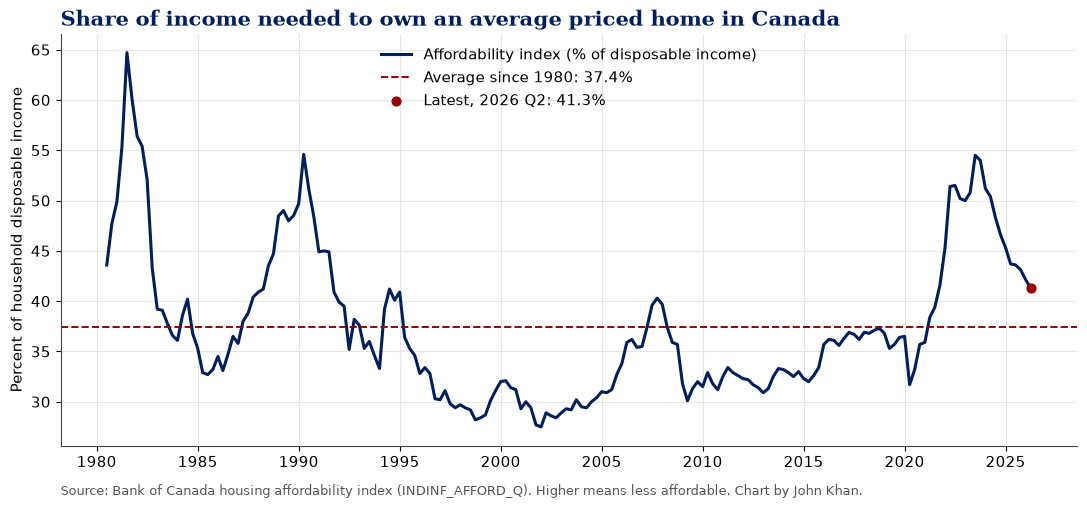

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(a.index, a, color=BLUE, lw=2.2, label="Affordability index (% of disposable income)")
ax.axhline(a.mean(), color=RED, lw=1.4, ls="--", label=f"Average since {a.index[0].year}: {a.mean():.1f}%")
ax.scatter([latest_q], [a.iloc[-1]], color=RED, zorder=5, s=40, label=f"Latest, {qlabel(latest_q)}: {a.iloc[-1]:.1f}%")
style(ax, "Share of income needed to own an average priced home in Canada", "Percent of household disposable income")
ax.legend(loc="upper center")
ax.text(0, -0.12, "Source: Bank of Canada housing affordability index (INDINF_AFFORD_Q). Higher means less affordable. Chart by John Khan.",
        transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "01_affordability_index.png")

## 3. How much do mortgage rates drive it?

The index has three moving parts: prices, rates and incomes. I cannot split them exactly with these series, but I can check how closely the index tracks the five year mortgage rate in levels and in yearly changes.

In [6]:
d = q.dropna(subset=["posted5"]).copy()
level_corr = d["afford_pct"].corr(d["posted5"])
y4 = d[["afford_pct", "posted5"]].diff(4).dropna()
change_corr = y4["afford_pct"].corr(y4["posted5"])
slope = np.polyfit(y4["posted5"], y4["afford_pct"], 1)[0]
print(f"Correlation of levels, {qlabel(d.index[0])} to {qlabel(d.index[-1])}: {level_corr:.2f}")
print(f"Correlation of 4 quarter changes: {change_corr:.2f}  (R squared {change_corr ** 2:.2f})")
print(f"Average change in the index per 1 point change in the posted 5 year rate over a year: {slope:.1f} pts")
since = d.loc["2000":]
y4s = since[["afford_pct", "posted5"]].diff(4).dropna()
print(f"Same, since 2000: correlation of 4 quarter changes {y4s['afford_pct'].corr(y4s['posted5']):.2f}, slope {np.polyfit(y4s['posted5'], y4s['afford_pct'], 1)[0]:.1f}")

Correlation of levels, 1980 Q3 to 2026 Q2: 0.57
Correlation of 4 quarter changes: 0.85  (R squared 0.72)
Average change in the index per 1 point change in the posted 5 year rate over a year: 3.1 pts
Same, since 2000: correlation of 4 quarter changes 0.65, slope 4.1


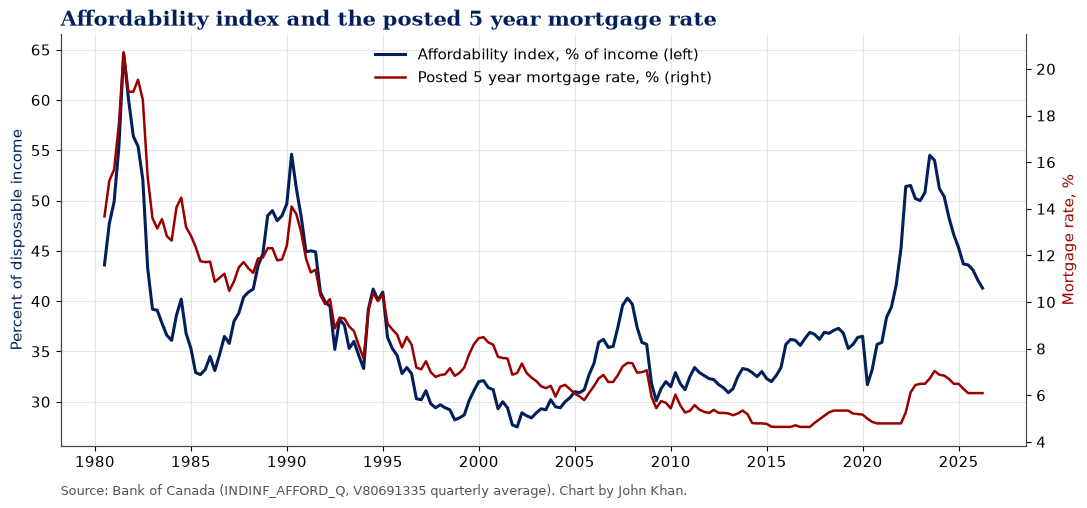

In [7]:
fig, ax1 = plt.subplots(figsize=(11, 5.2))
ax1.plot(d.index, d["afford_pct"], color=BLUE, lw=2.2, label="Affordability index, % of income (left)")
ax1.set_ylabel("Percent of disposable income", color=BLUE)
ax2 = ax1.twinx()
ax2.plot(d.index, d["posted5"], color=RED, lw=1.8, label="Posted 5 year mortgage rate, % (right)")
ax2.set_ylabel("Mortgage rate, %", color=RED)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
style(ax1, "Affordability index and the posted 5 year mortgage rate")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center")
ax1.text(0, -0.12, "Source: Bank of Canada (INDINF_AFFORD_Q, V80691335 quarterly average). Chart by John Khan.", transform=ax1.transAxes, fontsize=9, color="#555555")
save(fig, "02_affordability_vs_rate.png")

## 4. A check from the new home side

The affordability index uses resale prices. Statistics Canada's New Housing Price Index tracks builders' prices for the same kind of new house over time, so it is a useful second view on prices.

In [8]:
n = q["nhpi_yoy"].dropna()
neg = n[n < 0]
print(f"NHPI year over year, {qlabel(n.index[0])} to {qlabel(n.index[-1])}")
print(f"Latest: {n.iloc[-1]:+.1f}% in {qlabel(n.index[-1])}")
print(f"Peak: {n.max():+.1f}% in {qlabel(n.idxmax())}")
print(f"Quarters with falling new home prices: {len(neg)} of {len(n)}")
recent_neg = n.loc["2023":]
print(f"Since 2023: {int((recent_neg < 0).sum())} of {len(recent_neg)} quarters negative; lowest {recent_neg.min():+.1f}% in {qlabel(recent_neg.idxmin())}")
streak = 0
for v in n[::-1]:
    if v < 0: streak += 1
    else: break
print(f"Current run of negative quarters: {streak}")

NHPI year over year, 1993 Q1 to 2026 Q2
Latest: -2.3% in 2026 Q2
Peak: +11.8% in 2021 Q3
Quarters with falling new home prices: 26 of 134
Since 2023: 10 of 14 quarters negative; lowest -2.3% in 2026 Q2
Current run of negative quarters: 5


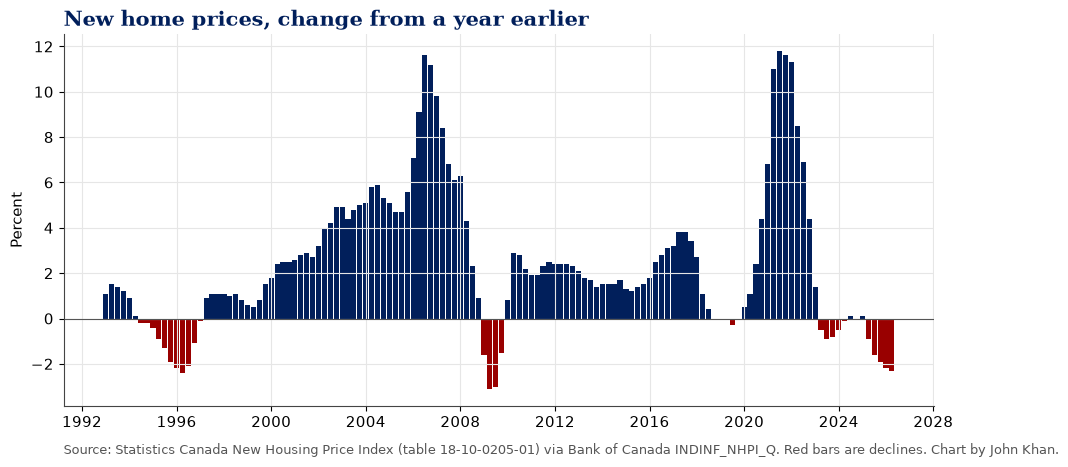

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8))
colors = [RED if v < 0 else BLUE for v in n]
ax.bar(n.index, n, width=80, color=colors)
ax.axhline(0, color="#555555", lw=0.8)
style(ax, "New home prices, change from a year earlier", "Percent")
ax.text(0, -0.13, "Source: Statistics Canada New Housing Price Index (table 18-10-0205-01) via Bank of Canada INDINF_NHPI_Q. Red bars are declines. Chart by John Khan.",
        transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "03_nhpi_yoy.png")

## 5. Conclusion

*Figures below are from the run on October 18, 2026, with the affordability index through 2026 Q2.*

**1. It is not the worst it has ever been, but it is still worse than usual.** In 2026 Q2 a household needed 41.3% of average disposable income to carry an average priced home, against a long run average of 37.4% since 1980. About 77% of past quarters were more affordable than today. The all time high was 64.7% in 1981 Q3, when the posted five year rate averaged 20.70%. The low was 27.5% in 2002 Q1.

**2. The 2020s spike matched the 1990 peak with rates a third as high.** The index jumped from 31.7% in 2020 Q2 to 54.5% in 2023 Q3, a rise of 22.8 points in about three years. That peak is almost the same as the 54.6% reached in 1990 Q2. The difference is that in 1990 the posted five year rate averaged 14.10%. In 2023 Q3 it averaged 6.72%. Prices relative to income are doing far more of the work now.

**3. Year to year, rates still drive most of the swings.** Over the full history, the yearly change in the index has a 0.85 correlation with the yearly change in the posted five year rate, and a 1 point move in that rate has gone with about a 3.1 point move in the index. In levels the link is much weaker (0.57), which is what you would expect if prices and incomes set the baseline and rates move it around.

**4. Affordability has improved in each of the last 11 quarters.** Since the 2023 Q3 peak the index is down 13.2 points to 41.3%. Over the same stretch the posted five year rate eased from 6.72% to 6.09%, and new home prices softened. On the price side, Statistics Canada's New Housing Price Index was down 2.3% from a year earlier in 2026 Q2, the fifth negative quarter in a row, and 10 of the 14 quarters since 2023 have been negative. That is a big turn from the +11.8% peak in 2021 Q3.

**What this means.** Buying is easier than it was in 2023, but a typical household still needs about 4 points more of its income for housing than the 45 year average. Getting back to average would take some mix of lower rates, flat prices and rising incomes for a while yet.


## Notes and limits

* The index is a national average. Toronto and Vancouver are far less affordable than the national figure, and many smaller markets are more affordable.
* It assumes a 95% loan to value ratio and a 25 year amortization for every period, so it shows the cost of buying today, not what existing owners pay.
* Correlation with the posted rate is a rough guide. The index uses a blended discounted rate, not the posted rate.
* Every figure is printed by the code from the data pulled on the run date.

*Data: Bank of Canada, Valet API, https://www.bankofcanada.ca/valet/docs (terms: https://www.bankofcanada.ca/terms/). New Housing Price Index: Statistics Canada, table 18-10-0205-01, https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=1810020501.*